In [1]:
# Nguồn 1: https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
# Nguồn 2: https://www.kaggle.com/datasets/carrie1/ecommerce-data
# CSV gốc đã có trong data_goc; không cần tải mạng khi chạy.


# STAGE 1 — CHUẨN BỊ VÀ PHÂN TÍCH DỮ LIỆU KHÁCH HÀNG THƯƠNG MẠI ĐIỆN TỬ

Thực hiện phần cơ bản của đề: đọc dữ liệu ngoài, sinh dữ liệu động bằng NumPy, chuẩn hóa và tích hợp, lưu và đọc lại từ hai loại CSDL, xử lý thiếu và EDA. Không làm Web Crawling hoặc sinh văn bản bằng AI (PLUS).

**Mục tiêu dữ liệu:** mỗi dòng cuối cùng là một khách hàng, phục vụ phân nhóm khách hàng và dự đoán giá trị mua / có mua lại ở giai đoạn sau. Notebook này chưa huấn luyện mô hình.

**Nguồn:** hai CSV trong `data_goc`, tải từ hai bộ Kaggle Online Retail II và Online Retail. Hai bộ cùng nhà bán lẻ, cùng nguồn gốc UCI, không phải hai cửa hàng độc lập. Dữ liệu có thời gian chồng lấn nên chia giai đoạn trước khi concat. Giá trị tiền dùng GBP theo nguồn.

**Phạm vi giữ từ notebook gốc:** lấy ngẫu nhiên 1.000 khách đã mua trong kỳ 01/03/2010 đến trước 01/09/2011, seed=42. Đặc trưng chỉ dùng kỳ này; kết quả mua lại và giá trị mua lấy từ 01/09/2011 đến trước 30/11/2011 (90 ngày). Không ghi nhận mua trong 90 ngày không có nghĩa rời bỏ vĩnh viễn.

**Cách chạy:** giải nén toàn bộ thư mục, mở notebook tại thư mục có `data_goc`, cài thư viện ở `requirements.txt`, chạy từ trên xuống. Code tạo lại các tệp kết quả và CSDL riêng trong `csdl`.


## 1. Nạp thư viện và đọc CSV gốc
Đề yêu cầu ít nhất hai nguồn liên quan và >=300 dòng. Dùng pandas, NumPy, matplotlib/seaborn, SQLite và Qdrant; không có pipeline ML, class tự viết hoặc API LLM.

In [2]:
# Nguồn 1: https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci
# Nguồn 2: https://www.kaggle.com/datasets/carrie1/ecommerce-data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from pathlib import Path
from IPython.display import display

Path('csdl').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
cu = pd.read_csv('data_goc/online_retail_II.csv', encoding='ISO-8859-1',
                 dtype={'Invoice': 'string', 'StockCode': 'string'})
moi = pd.read_csv('data_goc/online_retail.csv', encoding='ISO-8859-1',
                  dtype={'InvoiceNo': 'string', 'StockCode': 'string'})
print('Online Retail II:', cu.shape, '| Online Retail:', moi.shape)
display(cu.head(3))
display(moi.head(3))


Online Retail II: (1067371, 8) | Online Retail: (541909, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom


## 2. Kiểm tra và chuẩn hóa trước concat
Đổi tên Invoice/Price/Customer ID của bộ cũ cho giống bộ mới. Đọc ngày theo đúng định dạng từng file; chuẩn hóa mã khách về chuỗi, giá/số lượng về số. Không thay giá trị thiếu của mã khách bằng một mã giả.

In [3]:
cu = cu.rename(columns={'Invoice': 'InvoiceNo', 'Price': 'UnitPrice', 'Customer ID': 'CustomerID'})
print('Tên cột nguồn 1:', cu.columns.tolist())
print('Tên cột nguồn 2:', moi.columns.tolist())
print('Hai nguồn cùng tập cột:', set(cu.columns) == set(moi.columns))
moi = moi[cu.columns].copy()
cu['InvoiceDate'] = pd.to_datetime(cu['InvoiceDate'], format='%Y-%m-%d %H:%M:%S')
moi['InvoiceDate'] = pd.to_datetime(moi['InvoiceDate'], format='%m/%d/%Y %H:%M')
for bang in [cu, moi]:
    bang['CustomerID'] = pd.to_numeric(bang['CustomerID']).astype('Int64').astype('string')
    bang['UnitPrice'] = pd.to_numeric(bang['UnitPrice'])
    bang['Quantity'] = pd.to_numeric(bang['Quantity'])
    for cot in ['Description', 'Country']:
        bang[cot] = bang[cot].astype('string').str.strip().replace('', pd.NA)
    display(pd.DataFrame({'So_thieu': bang.isna().sum(), 'Phan_tram': bang.isna().mean()*100}))
print('Các mã/ngày dùng để ghép:')
display(cu.dtypes)


Tên cột nguồn 1: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Tên cột nguồn 2: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Hai nguồn cùng tập cột: True
Các mã/ngày dùng để ghép:


,So_thieu,Phan_tram
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,4382,0.410541
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,243007,22.766873
Country,0,0.000000


,So_thieu,Phan_tram
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


InvoiceNo      string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID     string[python]
Country        string[python]
dtype: object

## 3. Gộp dọc hai giai đoạn không chồng lấn
`concat` thêm dòng cho cùng loại đối tượng: dòng hóa đơn. Nhãn Source ghi nơi tải, không phải cửa hàng. Mã CustomerID có cùng ý nghĩa vì cùng nhà bán lẻ. Không thêm Source vào mã khách để chia một khách thành hai người.

In [4]:
moc_nguon = pd.Timestamp('2010-12-01')
phan_cu = cu[cu['InvoiceDate'] < moc_nguon].copy()
phan_moi = moi[moi['InvoiceDate'] >= moc_nguon].copy()
phan_cu['Source'] = 'OnlineRetailII'
phan_moi['Source'] = 'OnlineRetail'
df = pd.concat([phan_cu, phan_moi], ignore_index=True)
display(df.groupby('Source')['InvoiceDate'].agg(['count', 'min', 'max']))
print('Số dòng trùng đủ cột (chưa xóa):', df.duplicated().sum())


Số dòng trùng đủ cột (chưa xóa): 11812


,count,min,max
Source,,,
OnlineRetail,541909,2010-12-01 08:26:00,2011-12-09 12:50:00
OnlineRetailII,502938,2009-12-01 07:45:00,2010-11-30 19:35:00


## 4. Xác định phạm vi giao dịch và chọn mẫu khách
Chỉ dùng hóa đơn không bắt đầu bằng C, Quantity>0, UnitPrice>0, có mã khách để đo **giá trị mua dương**, không phải doanh thu ròng đã trừ hoàn trả. In riêng số dòng nằm ngoài phạm vi; không điền mã khách thiếu bằng mode/Unknown vì sẽ ghép nhầm nhiều người.

Mô tả sản phẩm có thể thiếu nhưng không cần cho RFM, không xóa vì thiếu mô tả. Các dòng trùng đủ cột được giữ vì không có mã dòng gốc để chứng minh là lỗi; giá trị mua là tổng dòng theo nguồn, chưa phải số tiền ngân hàng đã xác minh.

Chọn 1.000 mã khách bằng `sample(random_state=42)` từ kỳ quan sát, rồi giữ toàn bộ giao dịch hợp lệ của họ trong hai kỳ. Không đọc nhãn để chọn khách.

In [5]:
bat_dau = pd.Timestamp('2010-03-01')
moc_du_doan = pd.Timestamp('2011-09-01')
ket_thuc = moc_du_doan + pd.Timedelta(days=90)
print('Dòng thiếu mã khách:', df['CustomerID'].isna().sum())
print('Dòng hủy C:', df['InvoiceNo'].str.upper().str.startswith('C').sum())
print('Dòng số lượng không dương:', (df['Quantity'] <= 0).sum())
print('Dòng giá không dương:', (df['UnitPrice'] <= 0).sum())
hop_le = (df['CustomerID'].notna() & ~df['InvoiceNo'].str.upper().str.startswith('C')
          & (df['Quantity'] > 0) & (df['UnitPrice'] > 0))
mua = df[hop_le & (df['InvoiceDate'] >= bat_dau) & (df['InvoiceDate'] < ket_thuc)].copy()
khach_truoc = mua.loc[mua['InvoiceDate'] < moc_du_doan, 'CustomerID'].drop_duplicates().sort_values()
khach_chon = khach_truoc.sample(n=1000, random_state=42)
mua = mua[mua['CustomerID'].isin(khach_chon)].copy()
print('Khách đủ điều kiện:', len(khach_truoc), '| Khách được chọn:', len(khach_chon))
print('Dòng hợp lệ được dùng:', len(mua))
display(mua.groupby('Source').size())


Dòng thiếu mã khách: 235287
Dòng hủy C: 19165
Dòng số lượng không dương: 22557
Dòng giá không dương: 6029
Khách đủ điều kiện: 5015 | Khách được chọn: 1000
Dòng hợp lệ được dùng: 122669


Source
OnlineRetail      63218
OnlineRetailII    59451
dtype: int64

## 5. Tạo bảng hóa đơn tĩnh
Gom các dòng hàng thành hóa đơn bằng groupby: cộng giá trị Quantity×UnitPrice và số lượng; đếm mã hàng trong mỗi hóa đơn. Đây là đổi đơn vị từ dòng hàng sang hóa đơn để lưu gọn, không phải bịa dữ liệu.

Kiểm tra một InvoiceNo không thuộc nhiều khách; Country lấy ở dòng cuối của hóa đơn. Thời gian là ngày giờ theo nguồn, không tự gán UTC khi tài liệu không xác định múi giờ.

In [6]:
mua['LineAmountGBP'] = mua['Quantity'] * mua['UnitPrice']
mua = mua.sort_values('InvoiceDate')
hoa_don = mua.groupby('InvoiceNo', as_index=False).agg(
    CustomerID=('CustomerID', 'first'), InvoiceDate=('InvoiceDate', 'min'),
    Country=('Country', 'last'), Source=('Source', 'first'),
    AmountGBP=('LineAmountGBP', 'sum'), Units=('Quantity', 'sum'),
    ProductsInInvoice=('StockCode', 'nunique'))
hoa_don['RowID'] = np.arange(len(hoa_don))
print('Bảng tĩnh:', hoa_don.shape)
display(hoa_don.head())


Bảng tĩnh: (5847, 9)


,InvoiceNo,CustomerID,InvoiceDate,Country,Source,AmountGBP,Units,ProductsInInvoice,RowID
0,499511,16717,2010-03-01 08:55:00,United Kingdom,OnlineRetailII,347.50,121,14,0
1,499576,13948,2010-03-01 12:16:00,United Kingdom,OnlineRetailII,106.66,78,6,1
2,499624,17593,2010-03-01 13:10:00,United Kingdom,OnlineRetailII,669.71,365,26,2
3,499630,16273,2010-03-01 13:24:00,United Kingdom,OnlineRetailII,76.50,6,1,3
4,499637,12989,2010-03-01 13:45:00,United Kingdom,OnlineRetailII,313.10,106,3,4


## 6. Sinh dữ liệu động và merge
Đề bắt buộc sinh dữ liệu động. Chỉ sinh kênh liên hệ giả định cho mỗi khách bằng NumPy; ba kênh có xác suất bằng nhau, 4% để thiếu theo giả định minh họa. Đây không phải tỷ lệ khảo sát, không dùng trong feature hoặc insight hành vi thật.

Xuất CSV mô phỏng. Dùng **left join** để giữ mọi hóa đơn; nhiều hóa đơn thuộc một khách nên kiểm tra `many_to_one`.

In [7]:
mo_phong = pd.DataFrame({'CustomerID': sorted(khach_chon)})
rng = np.random.default_rng(42)
mo_phong['Kenh_lien_he_mo_phong'] = rng.choice(['Email', 'SMS', 'Phone'], len(mo_phong))
mo_phong.loc[rng.random(len(mo_phong)) < 0.04, 'Kenh_lien_he_mo_phong'] = None
mo_phong.to_csv('du_lieu_mo_phong.csv', index=False, encoding='utf-8-sig')
n_truoc = len(hoa_don)
hoa_don = pd.merge(hoa_don, mo_phong, on='CustomerID', how='left', validate='many_to_one')
display(hoa_don.head())


,InvoiceNo,CustomerID,InvoiceDate,Country,Source,AmountGBP,Units,ProductsInInvoice,RowID,Kenh_lien_he_mo_phong
0,499511,16717,2010-03-01 08:55:00,United Kingdom,OnlineRetailII,347.50,121,14,0,Email
1,499576,13948,2010-03-01 12:16:00,United Kingdom,OnlineRetailII,106.66,78,6,1,Email
2,499624,17593,2010-03-01 13:10:00,United Kingdom,OnlineRetailII,669.71,365,26,2,Email
3,499630,16273,2010-03-01 13:24:00,United Kingdom,OnlineRetailII,76.50,6,1,3,Phone
4,499637,12989,2010-03-01 13:45:00,United Kingdom,OnlineRetailII,313.10,106,3,4,Email


## 7. Lưu hai loại CSDL: SQLite và Qdrant
Đề yêu cầu hai loại CSDL. SQLite là quan hệ; Qdrant là vector, chạy local không cần tài khoản. Lưu toàn bộ hóa đơn vào payload Qdrant; vector chỉ gồm AmountGBP và Units để minh họa lưu trữ, không dùng khoảng cách này kết luận tương đồng. Không huấn luyện AI ở đây.

Chạy lại sẽ thay bảng/collection của bài tại `csdl`.

In [8]:
from qdrant_client import QdrantClient, models

de_luu = hoa_don.copy()
de_luu['InvoiceDate'] = de_luu['InvoiceDate'].dt.strftime('%Y-%m-%d %H:%M:%S')
de_luu = de_luu.astype(object).where(pd.notna(de_luu), None)
with sqlite3.connect('csdl/retail.sqlite') as conn:
    de_luu.to_sql('hoa_don', conn, if_exists='replace', index=False)

q = QdrantClient(path='csdl/qdrant')
if q.collection_exists('hoa_don'):
    q.delete_collection('hoa_don')
q.create_collection('hoa_don', vectors_config=models.VectorParams(size=2, distance=models.Distance.EUCLID))
points = []
for row in de_luu.to_dict('records'):
    points.append(models.PointStruct(id=int(row['RowID']),
        vector=[float(row['AmountGBP']), float(row['Units'])], payload=row))
q.upsert('hoa_don', points=points)
q.close()
print('Đã lưu', len(de_luu), 'hóa đơn vào cả hai CSDL.')


Đã lưu 5847 hóa đơn vào cả hai CSDL.


## 8. Đọc lại CSDL trước làm sạch và EDA
Mở kết nối mới; Qdrant đọc từng trang đến hết. So sánh toàn bộ bảng hai CSDL, không chỉ số dòng. Từ đây dữ liệu phân tích lấy từ SQLite.

In [9]:
with sqlite3.connect('csdl/retail.sqlite') as conn:
    tu_sql = pd.read_sql_query('SELECT * FROM hoa_don ORDER BY RowID', conn)
q = QdrantClient(path='csdl/qdrant')
rows = []
offset = None
while True:
    page, offset = q.scroll('hoa_don', limit=1000, offset=offset, with_payload=True, with_vectors=False)
    for point in page:
        rows.append(point.payload)
    if offset is None:
        break
q.close()
tu_q = pd.DataFrame(rows).sort_values('RowID').reset_index(drop=True)
print('Số dòng SQLite:', len(tu_sql))
print('Số dòng Qdrant:', len(tu_q))
print('Nội dung hai bảng giống nhau:', tu_sql.equals(tu_q[tu_sql.columns]))
hoa_don = tu_sql.copy()
hoa_don['InvoiceDate'] = pd.to_datetime(hoa_don['InvoiceDate'])
print('Đã đọc lại và đối chiếu đủ:', len(hoa_don), 'hóa đơn.')


Số dòng SQLite: 5847
Số dòng Qdrant: 5847
Nội dung hai bảng giống nhau: True
Đã đọc lại và đối chiếu đủ: 5847 hóa đơn.


## 9. Xử lý dữ liệu thiếu và so sánh trước/sau

Tính số lượng và phần trăm thiếu của từng cột sau khi đọc từ CSDL. Không tự sinh số tiền, mã khách hoặc ngày giao dịch để lấp chỗ trống. Dòng gốc thiếu mã khách được thống kê ở bước 4 và nằm ngoài phạm vi phân tích theo khách, vì không xác định được người mua.

Hàm `lam_sach` điền `Unknown` cho các cột phân loại còn thiếu. Các cột số ở bảng hóa đơn hợp lệ được kiểm tra không thiếu; vì vậy không cần điền median vào chúng. Không dùng ffill/bfill qua các hóa đơn của các khách khác nhau vì có thể gán thông tin người này cho người khác.

Kênh liên hệ là mô phỏng, bao gồm tỷ lệ thiếu giả định được ghi rõ ở bước 6; không xem đây là dữ liệu hành vi thật. So sánh bảng tần suất và tỷ lệ trước/sau, tách nhãn `Missing` trước xử lý và `Unknown` sau xử lý.


Số ô thiếu ở mã, ngày và số liệu giao dịch:
CustomerID           0
InvoiceDate          0
AmountGBP            0
Units                0
ProductsInInvoice    0
dtype: int64
Country
Kenh_lien_he_mo_phong
Tổng ô thiếu sau xử lý: 0


,So_thieu,Phan_tram
InvoiceNo,0,0.000000
CustomerID,0,0.000000
InvoiceDate,0,0.000000
Country,0,0.000000
Source,0,0.000000
AmountGBP,0,0.000000
Units,0,0.000000
ProductsInInvoice,0,0.000000
RowID,0,0.000000
Kenh_lien_he_mo_phong,205,3.506071


,So_luong_truoc,So_luong_sau,Ty_le_truoc,Ty_le_sau
Country,,,,
United Kingdom,5226,5226,89.379169,89.379169
Germany,280,280,4.788781,4.788781
France,139,139,2.377287,2.377287
Belgium,35,35,0.598598,0.598598
Sweden,28,28,0.478878,0.478878
Netherlands,15,15,0.256542,0.256542
Austria,15,15,0.256542,0.256542
Spain,13,13,0.222336,0.222336
Switzerland,11,11,0.188131,0.188131


,So_luong_truoc,So_luong_sau,Ty_le_truoc,Ty_le_sau
Kenh_lien_he_mo_phong,,,,
SMS,1930.0,1930.0,33.008380,33.008380
Email,1883.0,1883.0,32.204549,32.204549
Phone,1829.0,1829.0,31.280999,31.280999
Missing,205.0,0.0,3.506071,0.000000
Unknown,0.0,205.0,0.000000,3.506071


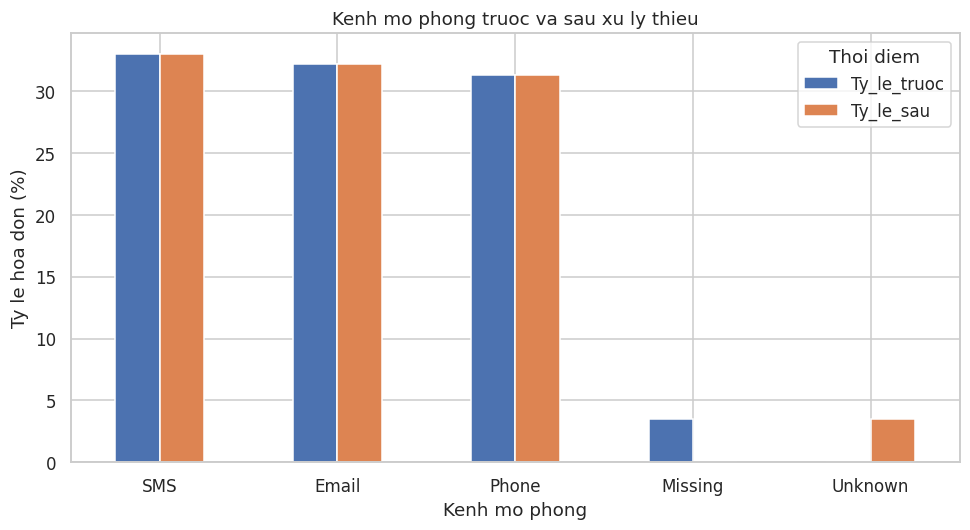

In [10]:
missing = pd.DataFrame({
    'So_thieu': hoa_don.isna().sum(),
    'Phan_tram': hoa_don.isna().mean() * 100
})
display(missing)
print('Số ô thiếu ở mã, ngày và số liệu giao dịch:')
print(hoa_don[['CustomerID', 'InvoiceDate', 'AmountGBP', 'Units', 'ProductsInInvoice']].isna().sum())

def lam_sach(bang):
    ket_qua = bang.copy()
    ket_qua['Country'] = ket_qua['Country'].fillna('Unknown')
    ket_qua['Kenh_lien_he_mo_phong'] = ket_qua['Kenh_lien_he_mo_phong'].fillna('Unknown')
    return ket_qua

truoc = hoa_don.copy()
hoa_don = lam_sach(hoa_don)
for cot in ['Country', 'Kenh_lien_he_mo_phong']:
    a = truoc[cot].fillna('Missing').value_counts()
    b = hoa_don[cot].value_counts()
    so_sanh = pd.concat([a, b], axis=1).fillna(0)
    so_sanh.columns = ['So_luong_truoc', 'So_luong_sau']
    so_sanh['Ty_le_truoc'] = so_sanh['So_luong_truoc'] / len(truoc) * 100
    so_sanh['Ty_le_sau'] = so_sanh['So_luong_sau'] / len(hoa_don) * 100
    print(cot)
    display(so_sanh)
so_sanh[['Ty_le_truoc', 'Ty_le_sau']].plot(kind='bar', rot=0)
plt.title('Kenh mo phong truoc va sau xu ly thieu')
plt.xlabel('Kenh mo phong'); plt.ylabel('Ty le hoa don (%)')
plt.legend(title='Thoi diem')
plt.tight_layout(); plt.show(); plt.close()
print('Tổng ô thiếu sau xử lý:', hoa_don.isna().sum().sum())


**Nhận xét — So what?** Nhóm `Missing` trước xử lý chuyển thành `Unknown` sau xử lý; các nhóm đã có thông tin giữ nguyên tần suất và tỷ lệ. Cách này giữ hóa đơn mà không đoán kênh liên hệ thật. Không có dữ liệu thiếu ở số tiền trong bảng đã chọn, nên không áp dụng điền số tùy ý. Kênh mô phỏng không dùng làm đặc trưng dự đoán hành vi khách hàng.


## 10. Tạo bảng một dòng/khách và nhãn thật
Feature chỉ dùng hóa đơn trước mốc 01/09/2011. Recency là số ngày từ lần mua cuối đến mốc; Frequency là số hóa đơn; Monetary là tổng giá trị mua dương. Các biến khác được tính từ cùng kỳ quan sát.

Target hồi quy là tổng giá trị mua dương trong 90 ngày kế tiếp. Target phân loại bằng 1 khi có ít nhất một hóa đơn trong kỳ đó. Điền **0** cho khách không có hóa đơn kỳ sau vì đây là định nghĩa nhãn từ cửa sổ quan sát đầy đủ, không phải impute tiền bị thiếu.

Country là giá trị quan sát cuối trước mốc. Không dùng dữ liệu sau mốc để chọn quốc gia hoặc tạo feature.

In [11]:
truoc_moc = hoa_don[hoa_don['InvoiceDate'] < moc_du_doan].copy()
sau_moc = hoa_don[(hoa_don['InvoiceDate'] >= moc_du_doan) & (hoa_don['InvoiceDate'] < ket_thuc)].copy()
data = truoc_moc.groupby('CustomerID', as_index=False).agg(
    LastPurchase=('InvoiceDate', 'max'), FirstPurchase=('InvoiceDate', 'min'),
    Frequency=('InvoiceNo', 'nunique'), MonetaryGBP=('AmountGBP', 'sum'),
    TotalUnits=('Units', 'sum'), AvgProductsPerInvoice=('ProductsInInvoice', 'mean'),
    Country=('Country', 'last'), Kenh_lien_he_mo_phong=('Kenh_lien_he_mo_phong', 'first'))
data['RecencyDays'] = (moc_du_doan-data['LastPurchase']).dt.days
data['ObservedTenureDays'] = (moc_du_doan-data['FirstPurchase']).dt.days
data['AvgOrderValueGBP'] = data['MonetaryGBP']/data['Frequency']
nhan = sau_moc.groupby('CustomerID', as_index=False).agg(
    Chi_tieu_90_ngay_GBP=('AmountGBP', 'sum'), So_don_90_ngay=('InvoiceNo', 'nunique'))
data = data.merge(nhan, on='CustomerID', how='left', validate='one_to_one')
data[['Chi_tieu_90_ngay_GBP', 'So_don_90_ngay']] = data[['Chi_tieu_90_ngay_GBP', 'So_don_90_ngay']].fillna(0)
data['Mua_lai_90_ngay'] = (data['So_don_90_ngay'] > 0).astype(int)
data['RegionGroup'] = np.where(data['Country'] == 'United Kingdom', 'United Kingdom', 'Other countries')
data = data.drop(columns=['LastPurchase', 'FirstPurchase', 'So_don_90_ngay'])
print('Bảng khách:', data.shape)
display(data.head())
display(data['Mua_lai_90_ngay'].value_counts())


Bảng khách: (1000, 13)


,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


Mua_lai_90_ngay
0    557
1    443
Name: count, dtype: int64

## 11. Thống kê đơn biến
Đủ mean, median, std, skewness, kurtosis; tần suất và tỷ lệ các biến phân loại. Kurtosis của pandas là excess kurtosis, phân phối chuẩn có giá trị 0.

In [12]:
cot_so = ['RecencyDays', 'Frequency', 'MonetaryGBP', 'TotalUnits',
          'AvgProductsPerInvoice', 'ObservedTenureDays', 'AvgOrderValueGBP', 'Chi_tieu_90_ngay_GBP']
tk = data[cot_so].describe().T
tk['median'] = data[cot_so].median()
tk['skewness'] = data[cot_so].skew()
tk['kurtosis'] = data[cot_so].kurt()
display(tk)
for cot in ['Country', 'RegionGroup', 'Mua_lai_90_ngay', 'Kenh_lien_he_mo_phong']:
    ts = data[cot].value_counts().to_frame('So_khach')
    ts['Phan_tram'] = ts['So_khach']/len(data)*100
    print(cot)
    display(ts)


Country
RegionGroup
Mua_lai_90_ngay
Kenh_lien_he_mo_phong


,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
RecencyDays,1000.0,180.595000,146.667359,0.00,48.000000,142.000000,295.000000,548.00,142.000000,0.565423,-0.782462
Frequency,1000.0,4.881000,7.184320,1.00,1.000000,3.000000,5.250000,91.00,3.000000,5.304762,43.481112
MonetaryGBP,1000.0,1949.327965,4553.095061,3.75,306.435000,722.505000,1829.777500,84946.96,722.505000,9.594686,136.952411
TotalUnits,1000.0,1196.167000,4042.469043,1.00,161.500000,395.500000,1041.750000,88457.00,395.500000,14.295166,260.763119
AvgProductsPerInvoice,1000.0,20.756110,18.965401,1.00,9.000000,16.111111,25.500000,220.00,16.111111,3.293435,21.423643
ObservedTenureDays,1000.0,368.812000,149.452175,1.00,289.750000,394.000000,503.000000,548.00,394.000000,-0.708952,-0.458022
AvgOrderValueGBP,1000.0,365.695925,514.416646,3.75,173.956667,276.453750,408.373333,13305.50,276.453750,16.670154,402.746802
Chi_tieu_90_ngay_GBP,1000.0,422.265840,1058.002243,0.00,0.000000,0.000000,474.962500,16074.50,0.000000,7.046750,73.724342


,So_khach,Phan_tram
Country,,
United Kingdom,902,90.2
Germany,24,2.4
France,18,1.8
Spain,7,0.7
Netherlands,6,0.6
Belgium,5,0.5
Sweden,5,0.5
Austria,4,0.4
Switzerland,3,0.3


,So_khach,Phan_tram
RegionGroup,,
United Kingdom,902,90.2
Other countries,98,9.8


,So_khach,Phan_tram
Mua_lai_90_ngay,,
0,557,55.7
1,443,44.3


,So_khach,Phan_tram
Kenh_lien_he_mo_phong,,
Phone,324,32.4
Email,322,32.2
SMS,317,31.7
Unknown,37,3.7


## 12. Histogram có KDE — giá trị mua kỳ quan sát
Xem hình dạng và độ lệch của MonetaryGBP, không suy luận chỉ từ mean.

Median: 722.5050000000001 | Skewness: 9.594685789701465


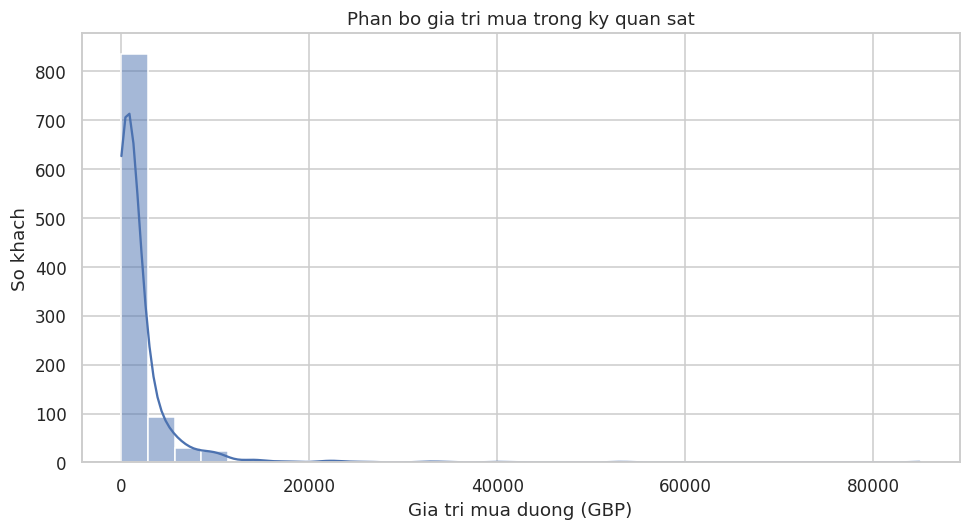

In [13]:
sns.histplot(data=data, x='MonetaryGBP', bins=30, kde=True)
plt.title('Phan bo gia tri mua trong ky quan sat')
plt.xlabel('Gia tri mua duong (GBP)'); plt.ylabel('So khach')
plt.tight_layout(); plt.show(); plt.close()
print('Median:', data['MonetaryGBP'].median(), '| Skewness:', data['MonetaryGBP'].skew())


**Nhận xét:** Mean MonetaryGBP là 1,949.33, median 722.51 GBP; skewness 9.59. Phân phối lệch phải, một số khách giá trị lớn kéo mean lên. Stage 2 cần chuẩn hóa trước PCA/K-Means và kiểm tra sai số hồi quy ở nhóm giá trị lớn; chưa biến đổi dữ liệu hoặc hứa điểm số cao.

## 13. IQR và boxplot — ngoại lệ
Tính fence bằng Q1−1,5×IQR và Q3+1,5×IQR. Chỉ phát hiện; không tự xóa người mua nhiều.

Q1: 306.435 | Q3: 1829.7775000000001 | IQR: 1523.3425000000002 | Ngoai fence: 109


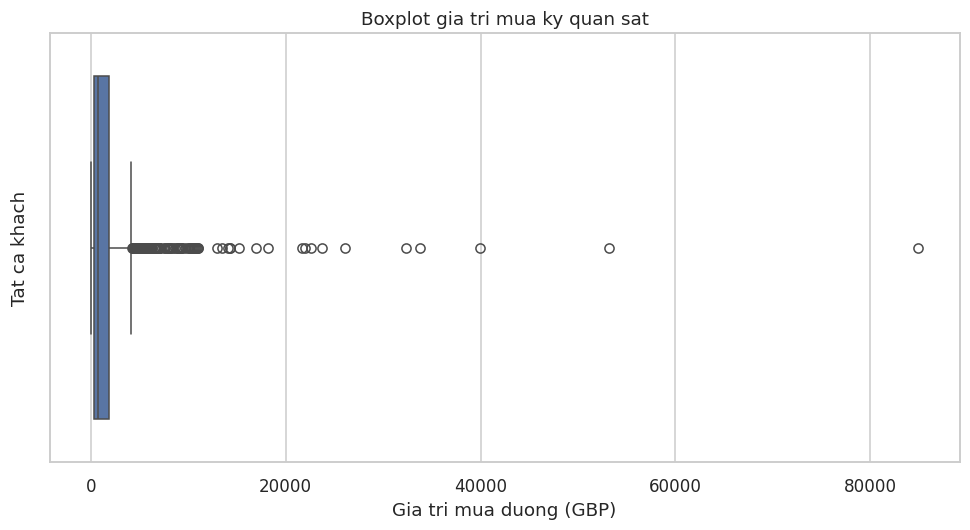

In [14]:
x = data['MonetaryGBP']
q1, q3 = x.quantile(0.25), x.quantile(0.75)
iqr = q3-q1
ngoai_le = (x < q1-1.5*iqr) | (x > q3+1.5*iqr)
print('Q1:', q1, '| Q3:', q3, '| IQR:', iqr, '| Ngoai fence:', ngoai_le.sum())
sns.boxplot(x=x)
plt.title('Boxplot gia tri mua ky quan sat')
plt.xlabel('Gia tri mua duong (GBP)'); plt.ylabel('Tat ca khach')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Có 109/1000 khách (10.9%) ngoài fence IQR. Giữ họ vì mua lớn có thể hợp lệ, nhất là dữ liệu có người mua sỉ theo tài liệu UCI. Ngoại lệ ảnh hưởng khoảng cách và sai số nên cần xem khi so sánh mô hình; không xóa chỉ để biểu đồ đẹp.

## 14. Bar chart — nhãn phân loại
Kiểm tra số lượng và tỷ lệ có/không mua lại trước khi quyết định xử lý mất cân bằng.

,So_khach,Phan_tram
Mua_lai_90_ngay,,
0,557,55.7
1,443,44.3


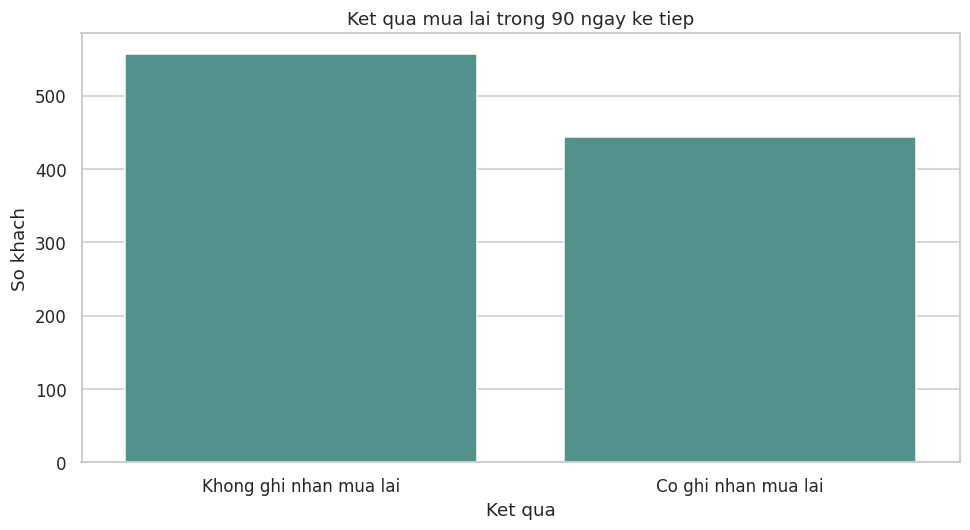

In [15]:
dem = data['Mua_lai_90_ngay'].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({'So_khach': dem, 'Phan_tram': dem/len(data)*100}))
sns.barplot(x=['Khong ghi nhan mua lai', 'Co ghi nhan mua lai'], y=dem.values, color='#499b95')
plt.title('Ket qua mua lai trong 90 ngay ke tiep')
plt.xlabel('Ket qua'); plt.ylabel('So khach')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét — So what?** Có 443 khách mua lại (44,3%) và 557 khách không ghi nhận mua lại (55,7%) trong mẫu. Hai nhóm không chênh lệch quá lớn. Khi làm phân loại cần kiểm tra tỷ lệ hai nhóm và đánh giá thêm Precision, Recall, F1 ngoài Accuracy. Nhãn chỉ phản ánh kết quả trong 90 ngày.


## 15. Heatmap — tương quan giữa các biến số
Dùng Spearman để xem quan hệ khi dữ liệu có phân phối lệch. Đưa hai nhãn vào bảng tương quan để xem quan hệ với đặc trưng; không được dùng nhãn làm đầu vào mô hình.


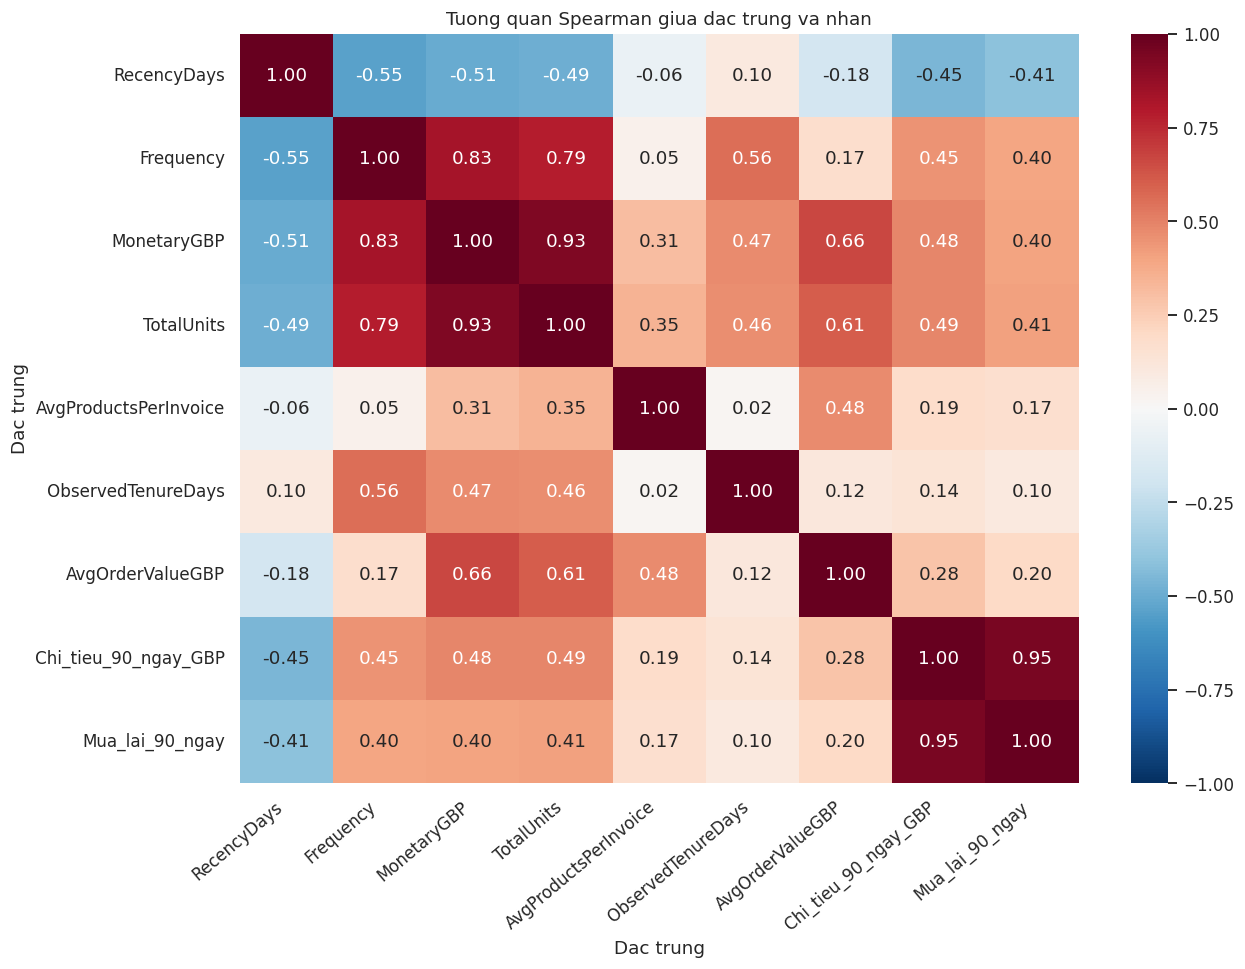

In [16]:
features = ['RecencyDays', 'Frequency', 'MonetaryGBP', 'TotalUnits',
            'AvgProductsPerInvoice', 'ObservedTenureDays', 'AvgOrderValueGBP']
cor = data[features + ['Chi_tieu_90_ngay_GBP', 'Mua_lai_90_ngay']].corr(method='spearman')
plt.figure(figsize=(12, 9))
sns.heatmap(cor, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Tuong quan Spearman giua dac trung va nhan')
plt.xlabel('Dac trung'); plt.ylabel('Dac trung')
plt.xticks(rotation=40, ha='right')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Spearman Frequency–MonetaryGBP = 0.832, MonetaryGBP–TotalUnits = 0.932. Các biến chia sẻ thông tin; AvgOrderValueGBP còn được tính trực tiếp từ MonetaryGBP/Frequency. Đây là cơ sở thử PCA sau chuẩn hóa và so sánh K-Means có/không PCA, không chứng minh PCA chắc chắn cải thiện kết quả.

## 16. Scatter — feature và target hồi quy
Vẽ MonetaryGBP kỳ trước so với giá trị mua dương kỳ sau. Các điểm ở y=0 là khách không có hóa đơn mua dương trong 90 ngày.

Pearson: 0.6610436900657811


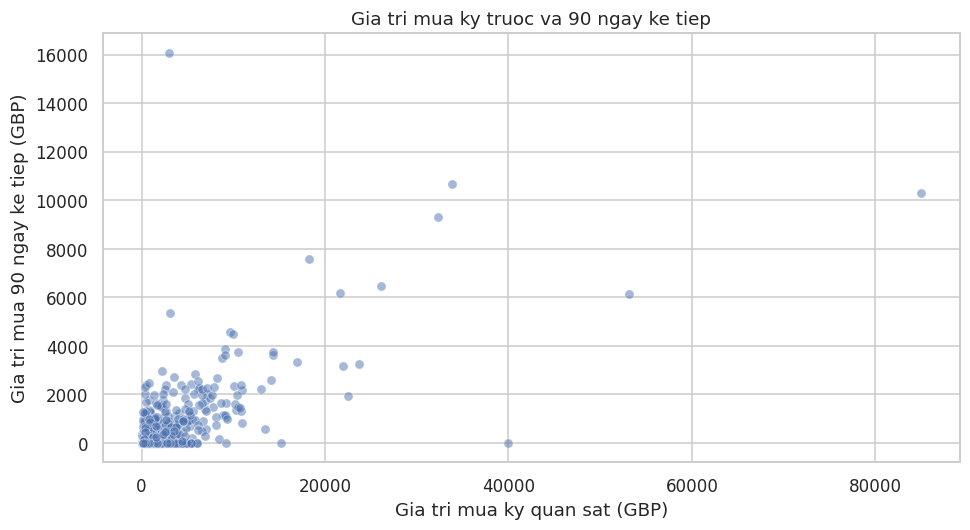

In [17]:
sns.scatterplot(data=data, x='MonetaryGBP', y='Chi_tieu_90_ngay_GBP', alpha=0.5)
plt.title('Gia tri mua ky truoc va 90 ngay ke tiep')
plt.xlabel('Gia tri mua ky quan sat (GBP)'); plt.ylabel('Gia tri mua 90 ngay ke tiep (GBP)')
plt.tight_layout(); plt.show(); plt.close()
print('Pearson:', data['MonetaryGBP'].corr(data['Chi_tieu_90_ngay_GBP']))


**Nhận xét — So what?** Tương quan Pearson giữa MonetaryGBP kỳ trước và giá trị mua kỳ sau xấp xỉ 0,661. Có 557 khách có giá trị kỳ sau bằng 0 vì không ghi nhận mua dương trong 90 ngày. Chi tiêu trước đây có quan hệ với chi tiêu kỳ sau nhưng không dự đoán chính xác từng khách; khi làm hồi quy cần kiểm tra sai số, đặc biệt ở nhóm mua lớn.


## 17. Groupby và grouped boxplot — feature theo target
So sánh Recency giữa nhóm mua lại/không mua lại. Recency nhỏ nghĩa là lần mua cuối gần mốc dự đoán hơn.

,count,mean,median,std
Mua_lai_90_ngay,,,,
0,557,233.276481,265.0,147.113653
1,443,114.356659,70.0,116.190276


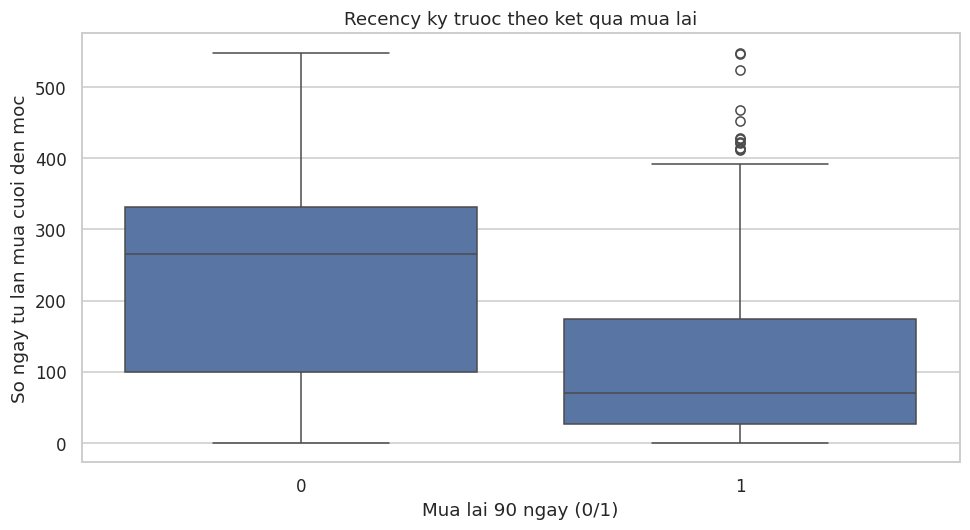

In [18]:
display(data.groupby('Mua_lai_90_ngay')['RecencyDays'].agg(['count', 'mean', 'median', 'std']))
sns.boxplot(data=data, x='Mua_lai_90_ngay', y='RecencyDays', order=[0, 1])
plt.title('Recency ky truoc theo ket qua mua lai')
plt.xlabel('Mua lai 90 ngay (0/1)'); plt.ylabel('So ngay tu lan mua cuoi den moc')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Median Recency của nhóm không mua lại là 265.0 ngày, nhóm mua lại là 70.0 ngày. Trong mẫu, nhóm mua lại có lần mua cuối gần mốc hơn. Recency là feature biết trước kết quả, đáng thử cho phân loại; quan hệ quan sát không bảo đảm dự đoán chính xác từng khách hoặc chứng minh mua gần gây mua lại.

## 18. Crosstab và stacked bar — hai biến phân loại
So sánh tỷ lệ mua lại giữa khách ở UK và các quốc gia khác. Dùng nhóm địa lý từ Country thật để biểu đồ dễ đọc; không gán quốc gia cho khách không biết.

Mua_lai_90_ngay,0,1
RegionGroup,,
Other countries,51,47
United Kingdom,506,396


Mua_lai_90_ngay,0,1
RegionGroup,,
Other countries,52.040816,47.959184
United Kingdom,56.097561,43.902439


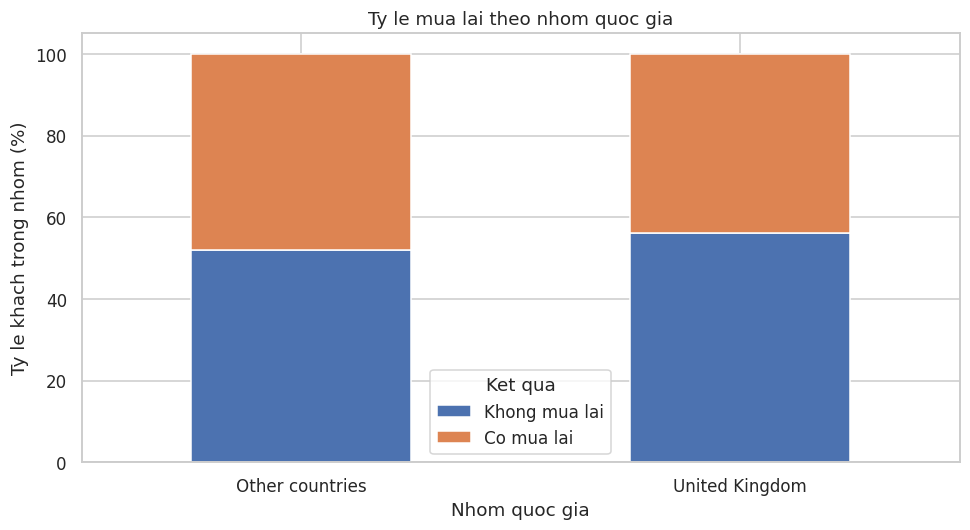

In [19]:
cheo = pd.crosstab(data['RegionGroup'], data['Mua_lai_90_ngay']).reindex(columns=[0, 1], fill_value=0)
display(cheo)
ty_le = cheo.div(cheo.sum(axis=1), axis=0)*100
display(ty_le)
ty_le.rename(columns={0: 'Khong mua lai', 1: 'Co mua lai'}).plot(kind='bar', stacked=True, rot=0)
plt.title('Ty le mua lai theo nhom quoc gia')
plt.xlabel('Nhom quoc gia'); plt.ylabel('Ty le khach trong nhom (%)'); plt.legend(title='Ket qua')
plt.tight_layout(); plt.show(); plt.close()


**Nhận xét:** Tỷ lệ mua lại theo nhóm: Other countries: 48.0%; United Kingdom: 43.9%. Cỡ mẫu các nhóm khác nhau nên dùng tỷ lệ cùng bảng số lượng. Không suy rộng thành quốc gia gây mua lại; tập khách thuộc một nhà bán lẻ và có thể có người mua sỉ. Bộ X cơ bản chỉ dùng các biến số để tránh phải mã hóa Country ở bản đầu.

## 19. Kiểm tra và xuất file sạch chính
Một dòng/khách, đủ nhãn, không thiếu. Lưu thêm bảng khách trong SQLite. Không xuất các file thống kê trung gian hoặc ảnh rời.

In [20]:
print('Số khách:', len(data))
print('Mỗi khách một dòng:', data['CustomerID'].is_unique)
print('Số ô thiếu:', data.isna().sum().sum())
print('Nhãn mua lại:', sorted(data['Mua_lai_90_ngay'].unique()))
print('Giá trị mua kỳ sau không âm:', (data['Chi_tieu_90_ngay_GBP'] >= 0).all())
print('Đặc trưng chỉ dùng trước mốc:', (truoc_moc['InvoiceDate'] < moc_du_doan).all())
print('Nhãn chỉ dùng từ mốc trở đi:', (sau_moc['InvoiceDate'] >= moc_du_doan).all())
data.to_csv('data_khach_hang.csv', index=False, encoding='utf-8-sig')
with sqlite3.connect('csdl/retail.sqlite') as conn:
    data.to_sql('khach_hang', conn, if_exists='replace', index=False)
print('Đã xuất data_khach_hang.csv:', data.shape)


Số khách: 1000
Mỗi khách một dòng: True
Số ô thiếu: 0
Nhãn mua lại: [np.int64(0), np.int64(1)]
Giá trị mua kỳ sau không âm: True
Đặc trưng chỉ dùng trước mốc: True
Nhãn chỉ dùng từ mốc trở đi: True
Đã xuất data_khach_hang.csv: (1000, 13)


## Kết quả Stage 1

- `data_goc/`: hai CSV gốc, không sửa dữ liệu nguồn.
- `du_lieu_mo_phong.csv`: kênh liên hệ giả định theo khách, sinh bằng NumPy.
- `csdl/`: dữ liệu được lưu và đọc lại từ SQLite và Qdrant local.
- `data_khach_hang.csv`: bảng sạch, một dòng mỗi khách.

| Cột | Ý nghĩa |
|---|---|
| CustomerID | Mã khách, không dùng làm đặc trưng số |
| RecencyDays | Số ngày từ lần mua cuối đến mốc 01/09/2011 |
| Frequency | Số hóa đơn trong kỳ quan sát |
| MonetaryGBP | Tổng giá trị mua dương trong kỳ quan sát |
| TotalUnits | Tổng số lượng mua trong kỳ quan sát |
| AvgProductsPerInvoice | Trung bình số mã hàng khác nhau mỗi hóa đơn |
| ObservedTenureDays | Số ngày từ lần mua đầu được quan sát đến mốc |
| AvgOrderValueGBP | Giá trị mua trung bình mỗi hóa đơn |
| Country / RegionGroup | Quốc gia ghi nhận cuối trước mốc / nhóm UK và các nước khác |
| Kenh_lien_he_mo_phong | Dữ liệu giả định, không dùng kết luận hành vi thật |
| Chi_tieu_90_ngay_GBP | Tổng giá trị mua dương trong 90 ngày tiếp theo, nhãn hồi quy |
| Mua_lai_90_ngay | 1 nếu có mua dương trong 90 ngày tiếp theo, ngược lại 0 |

Giá trị mua dương chưa trừ hoàn trả nên không gọi là doanh thu ròng. Không dùng hai nhãn tương lai, mã khách hoặc kênh mô phỏng làm đặc trưng. Các nhận xét EDA chỉ áp dụng cho mẫu khách đã chọn; không đại diện toàn bộ thị trường. Không tự xóa các dòng giống nhau vì dữ liệu không có mã dòng để xác minh chúng là lỗi ghi lặp.
